# Single-cell ATAC-seq part 4: differentially accessible regions

**Case study: Can liver cell types and hepatocyte zonation be recovered from chromatin accessibility alone?**

Bravo González-Blas C, et al. *Single-cell spatial multi-omics and deep learning dissect enhancer-driven gene regulatory networks in liver zonation.* Nature Cell Biology (2024). https://doi.org/10.1038/s41556-023-01316-4

**Research questions:**

1. Can the cell types of the liver be recovered from accessibility alone, without RNA?
2. Is hepatocyte zonation (periportal versus pericentral) visible in the chromatin?
3. Which regions differ between pericentral and periportal hepatocytes, and are they near known zonated genes?

This notebook answers question 3, compares our results with the paper, and ends with a conclusion on all three questions.

## Introduction

Differentially accessible regions (**DARs**) are regions that are more accessible in one group of cells than in another. In bulk ([part 3 of the bulk ATAC-seq practical](../bulk-atac-seq/part_3_diffbind_deseq2.ipynb)) we compared groups of mice. In single-cell data we compare groups of **cells**, which raises new questions:

- **Cell-type DARs** (one cell type versus all others) mark cell identity: these are candidate enhancers of each cell type.
- **Within a cell type**, e.g. pericentral versus periportal hepatocytes, the differences are smaller and more gradual.
- Cells are not independent replicates: thousands of cells come from just two mice. Methods that treat each cell as a replicate can report very small p-values for differences that would not replicate in another mouse. Including the sample as a covariate, or checking that a DAR holds in each mouse, helps.

We use two tools:

1. **SnapATAC2**: `marker_regions` for cell-type markers, and `diff_test` (a regression test on the peak matrix) for zonation, run in each mouse separately;
2. **pycisTopic**: `find_diff_features`, a Wilcoxon test on the **imputed accessibility** from the topic model (the topics smooth the sparse data).

Then we compare the zonation DARs of both tools, check them at known zonated genes, and make pseudobulk coverage tracks to look at them in a genome browser.

## Step 0: Setup

This notebook uses the `atac-sc` environment and the "Python (atac-sc)" kernel; see [part 1](part_1_qc_preprocessing.ipynb) for how to install them. Input data are in the folder `data` next to this notebook, our results go to `data/results/part_4`.

In [1]:
%matplotlib inline
import os
import pickle
import warnings

# set before the imports: no progress bars (diff_test prints one line per region) and no warnings
os.environ["TQDM_DISABLE"] = "1"
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import snapatac2 as snap
import pyranges as pr
from pycisTopic.diff_features import impute_accessibility, normalize_scores, find_diff_features

plt.rcParams["figure.dpi"] = 80

# The folder of this notebook (the kernel starts there). Kept when you run this cell again after os.chdir below.
HERE = globals().get("HERE", os.getcwd())

# Input data, in the folder data next to this notebook; your own results in data/results
SC = f"{HERE}/data"
GENOME = f"{SC}/genome"
OUT = f"{SC}/results/part_4"
os.makedirs(OUT, exist_ok=True)
os.chdir(OUT)

def results_of(part, filename):
    """Path to a result of an earlier part: yours if it exists, otherwise the pre-generated one."""
    mine = f"{SC}/results/{part}/{filename}"
    return mine if os.path.exists(mine) else f"{SC}/data_generated/{filename}"

adata = sc.read_h5ad(results_of("part_3", "liver_peaks_snapatac2.h5ad"))
with open(results_of("part_2", "cistopic_obj.pkl"), "rb") as f:
    cistopic_obj = pickle.load(f)
print(adata.shape, "|", cistopic_obj)

(11297, 203415) | CistopicObject from project cisTopic_merge with n_cells × n_regions = 11297 × 203393


## Step 1: Cell-type DARs with SnapATAC2

`snap.tl.marker_regions` aggregates the cells of each cell type into a pseudobulk and selects regions that are specifically accessible in one group compared with the others.

In [2]:
# a dict: cell type -> its marker regions (pvalue: significance threshold)
markers = snap.tl.marker_regions(adata, groupby="cell_type", pvalue=0.01)
pd.Series({cell_type: len(regions) for cell_type, regions in markers.items()}, name="marker regions").sort_values()

Fibroblast     2714
VEC            2981
B_cell         3472
DC             4298
MSC            4965
T_cell         5239
LSEC           6777
BEC            8246
HSC            8904
Kupffer       11916
Hepatocyte    31117
Name: marker regions, dtype: int64

A heatmap of the mean accessibility of each cell type's marker regions (rows: regions, columns: cell types) shows how specific they are:

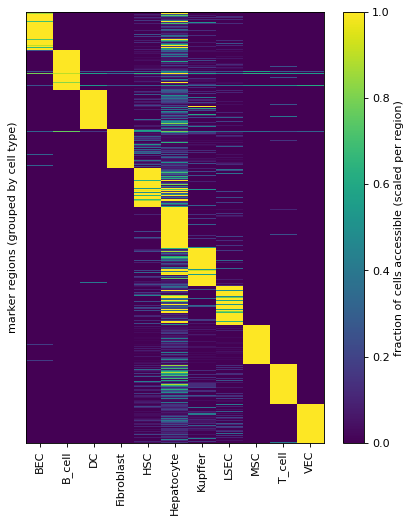

In [3]:
cell_types = sorted(markers)
top = [r for ct in cell_types for r in markers[ct][:100]]  # up to 100 marker regions per cell type
binary = adata[:, top].X > 0  # accessible or not, per cell and region
# fraction of accessible cells per cell type (columns) and region (rows); each row is then scaled to its maximum
mean_acc = pd.DataFrame(
    {ct: np.asarray(binary[(adata.obs["cell_type"] == ct).values].mean(axis=0)).ravel() for ct in cell_types},
    index=top)
fig, ax = plt.subplots(figsize=(6, 7))
im = ax.imshow((mean_acc / mean_acc.max(axis=1).values[:, None]).values, aspect="auto", cmap="viridis", interpolation="none")
ax.set_xticks(range(len(cell_types)), cell_types, rotation=90)
ax.set_yticks([])
ax.set_ylabel("marker regions (grouped by cell type)")
plt.colorbar(im, label="fraction of cells accessible (scaled per region)")
plt.show()

## Step 2: Zonation DARs with SnapATAC2

Now within hepatocytes: pericentral (PC) versus periportal (PP). `snap.tl.diff_test` fits a logistic regression per region on the cells of the two groups. It treats every cell as an independent observation, and it cannot (yet) include the mouse as a covariate. So we test **each mouse separately** and keep the regions that are significant in both mice, with the same direction: a difference that replicates in two animals, processed with two different protocols.

We test peaks accessible in at least 5% of the cells of one of the groups (`min_pct`) with a minimal log2 fold change of 0.25. This takes about 8 minutes.

Some barcodes occur in both samples, so cell names are not unique in `adata`; we give `diff_test` the cells as positions (row numbers) instead of names.

In [4]:
zone = adata.obs["zone"].values
mouse = adata.obs["sample"].values
per_mouse = {}
for m in sorted(set(mouse)):
    # positions (row numbers) of the PC and PP hepatocytes of this mouse
    pc = np.where((zone == "PC") & (mouse == m))[0].tolist()
    pp = np.where((zone == "PP") & (mouse == m))[0].tolist()
    result = snap.tl.diff_test(adata, cell_group1=pc, cell_group2=pp, direction="both",
                               min_log_fc=0.25, min_pct=0.05).to_pandas().set_index("feature name")
    per_mouse[m] = result
    sig = result[result["adjusted p-value"] < 0.05]
    print(f"{m}: {len(pc)} PC vs {len(pp)} PP hepatocytes, {len(result)} regions tested, "
          f"{(sig['log2(fold_change)'] > 0).sum()} up in PC, {(sig['log2(fold_change)'] < 0).sum()} up in PP")

# keep regions tested in both mice, significant in both, with the same direction
# join="inner": only regions tested in both mice; np.sign(fc).nunique() == 1: same sign in both
snap_zone = pd.concat(per_mouse, axis=1, join="inner")
fc = snap_zone.xs("log2(fold_change)", axis=1, level=1)
padj = snap_zone.xs("adjusted p-value", axis=1, level=1)
consistent = (padj < 0.05).all(axis=1) & (np.sign(fc).nunique(axis=1) == 1)
snap_dars = pd.DataFrame({"log2(fold_change)": fc.mean(axis=1), "max adjusted p-value": padj.max(axis=1)})[consistent]
print(f"significant in both mice: {(snap_dars['log2(fold_change)'] > 0).sum()} up in PC, "
      f"{(snap_dars['log2(fold_change)'] < 0).sum()} up in PP")
snap_dars.sort_values("max adjusted p-value").head()

Mouse_4_10x: 1556 PC vs 3695 PP hepatocytes, 19123 regions tested, 8776 up in PC, 6100 up in PP
Mouse_5_NST: 758 PC vs 2058 PP hepatocytes, 15658 regions tested, 3802 up in PC, 3678 up in PP
significant in both mice: 2329 up in PC, 1782 up in PP


2026-10-28 23:10:24 - INFO - Input contains 203415 features, now perform filtering with 'min_log_fc = 0.25' and 'min_pct = 0.05' ...
2026-10-28 23:10:35 - INFO - Testing 19123 features ...
2026-10-28 23:15:28 - INFO - Input contains 203415 features, now perform filtering with 'min_log_fc = 0.25' and 'min_pct = 0.05' ...
2026-10-28 23:15:38 - INFO - Testing 15658 features ...


,log2(fold_change),max adjusted p-value
feature name,,
chr5:120471461-120471962,-3.797524,6.108306e-90
chr7:140775844-140776345,3.981337,1.986581e-76
chr7:132616924-132617425,4.432893,3.441363e-75
chr1:153855850-153856351,5.740827,2.023424e-73
chr1:153911365-153911866,5.909509,4.220227e-73


## Step 3: Zonation DARs with pycisTopic

pycisTopic first **imputes** accessibility: the probability that a region is accessible in a cell is the product of the cell-topic and topic-region distributions. This turns the sparse 0/1 matrix into a smooth one, in which a region can have a high value even in a cell where no fragment was observed, if the cell's topics predict it. The imputed values are normalised and compared between groups with a Wilcoxon test.

Imputing and testing all cells × all 200,000 regions would take more than an hour, so we restrict it to the PP and PC hepatocytes and to the ~28,000 regions SnapATAC2 tested in at least one mouse (accessible in at least 5% of the cells of one zone). Both tools then test the same candidates, which also makes the comparison fairer. This takes about a minute.

In [5]:
# test the regions SnapATAC2 tested in at least one mouse (accessible in >= 5% of the cells of one zone),
# so both tools look at the same candidates; testing all 200,000 regions would take more than an hour
tested = sorted(set().union(*[result.index for result in per_mouse.values()]) & set(cistopic_obj.region_names))
hepatocytes = cistopic_obj.cell_data.index[cistopic_obj.cell_data["zone"].isin(["PP", "PC"])].tolist()
print(len(tested), "regions,", len(hepatocytes), "hepatocytes")

imputed = impute_accessibility(cistopic_obj, selected_cells=hepatocytes, selected_regions=tested, scale_factor=10**6)
normalized = normalize_scores(imputed, scale_factor=10**4)

# contrasts: PC vs PP and PP vs PC; thresholds: adjusted p < 0.05 and fold change > 1.5
pycistopic_zone = find_diff_features(
    cistopic_obj, normalized, variable="zone",
    contrasts=[[["PC"], ["PP"]], [["PP"], ["PC"]]],
    adjpval_thr=0.05, log2fc_thr=np.log2(1.5), n_cpu=4)
for name, table in pycistopic_zone.items():
    print(name, len(table), "DARs")
pycistopic_zone["PC_VS_PP"].head()

27947 regions, 8067 hepatocytes
PC_VS_PP 4718 DARs
PP_VS_PC 1561 DARs


2026-10-28 23:17:48 - INFO - Imputing region accessibility
2026-10-28 23:17:48 - INFO - Impute region accessibility for regions 0-20000
2026-10-28 23:17:48 - INFO - Impute region accessibility for regions 20000-40000
2026-10-28 23:17:49 - INFO - Done!
2026-10-28 23:17:49 - INFO - Normalizing imputed data
2026-10-28 23:17:50 - INFO - Done!
2026-10-28 23:17:51,013	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html
2026-10-28 23:17:57,255	INFO worker.py:2033 -- Started a local Ray instance.
2026-10-28 23:17:57 - INFO - Subsetting data for PC_VS_PP (2314 of 8067)
2026-10-28 23:18:03 - INFO - Computing p-value for PC_VS_PP
2026-10-28 23:18:12 - INFO - Computing log2FC for PC_VS_PP
2026-10-28 23:18:13 - INFO - PC_VS_PP done!
2026-10-28 23:18:13 - INFO - Subsetting data for PP_VS_PC (5753 of 8067)
2026-10-28 23:18:13 - INFO 

,Log2FC,Adjusted_pval,Contrast
chr2:97126792-97127293,5.802849,0.0,PC_VS_PP
chr1:153855286-153855787,5.770353,0.0,PC_VS_PP
chr2:159614970-159615471,5.397094,0.0,PC_VS_PP
chr14:54121239-54121740,5.278269,0.0,PC_VS_PP
chr2:94259152-94259653,5.243733,0.0,PC_VS_PP


## Step 4: Comparing the two tools

Both tools test the same consensus peaks, so we can compare region by region. How many PC and PP DARs are shared?

In [6]:
# sets of region names, so we can intersect them with &; positive log2 fold change = more accessible in PC
snap_pc = set(snap_dars.index[snap_dars["log2(fold_change)"] > 0])
snap_pp = set(snap_dars.index[snap_dars["log2(fold_change)"] < 0])
cis_pc = set(pycistopic_zone["PC_VS_PP"].index)
cis_pp = set(pycistopic_zone["PP_VS_PC"].index)
pd.DataFrame({
    "SnapATAC2": [len(snap_pc), len(snap_pp)],
    "pycisTopic": [len(cis_pc), len(cis_pp)],
    "both": [len(snap_pc & cis_pc), len(snap_pp & cis_pp)],
    "opposite direction": [len(snap_pc & cis_pp), len(snap_pp & cis_pc)],
}, index=["up in PC", "up in PP"])

,SnapATAC2,pycisTopic,both,opposite direction
up in PC,2329,4718,1502,0
up in PP,1782,1561,739,0


You should find about 2,300 PC and 1,800 PP DARs with SnapATAC2, and about 4,700 PC and 1,600 PP DARs with pycisTopic. About 1,500 PC and 740 PP DARs are found by both, and no region is called in opposite directions: the tools agree on the direction, but not on how many regions pass the threshold. Regions found by both, in the same direction, are the most robust candidates; we call them **robust DARs** below.

**Question**: Why do the two tools give such different numbers of DARs? (Hint: what does each tool test, on which data, and how does it treat the two mice?)

## Step 5: Are the DARs near zonated genes?

A simple sanity check: link each DAR to the nearest gene TSS, and look at the genes near the robust PC and PP DARs. We expect classic pericentral genes (*Cyp2e1*, *Glul*, *Oat*, *Axin2*) near PC DARs and periportal genes (*Cyp2f2*, *Hal*, *Sds*, *Pck1*) near PP DARs.

In [7]:
tss = pr.read_bed(f"{GENOME}/mm10_tss_protein_coding.bed").df.rename(columns={"Name": "gene"})
tss = pr.PyRanges(tss)

def nearest_genes(regions):
    """Nearest protein-coding TSS of each region (chr:start-end strings)."""
    df = pd.Series(list(regions)).str.extract(r"(?P<Chromosome>[^:]+):(?P<Start>\d+)-(?P<End>\d+)").astype({"Start": int, "End": int})
    df["region"] = list(regions)
    # nearest(): for every region the closest TSS, with the distance in bp
    hits = pr.PyRanges(df).nearest(tss).df
    return hits.set_index("region")[["gene", "Distance"]]

# robust DARs: found by both tools, in the same direction
robust_pc = snap_pc & cis_pc
robust_pp = snap_pp & cis_pp
genes_pc = nearest_genes(robust_pc)
genes_pp = nearest_genes(robust_pp)
zonated = ["Cyp2e1", "Glul", "Oat", "Axin2", "Lgr5", "Cyp1a2", "Cyp2f2", "Hal", "Sds", "Cps1", "Pck1", "Arg1", "Cyp7a1"]
print("near robust PC DARs:", sorted(set(genes_pc["gene"]) & set(zonated)))
print("near robust PP DARs:", sorted(set(genes_pp["gene"]) & set(zonated)))

near robust PC DARs: ['Axin2', 'Cyp1a2', 'Cyp2e1', 'Cyp7a1', 'Glul', 'Lgr5', 'Oat']
near robust PP DARs: ['Arg1', 'Cps1', 'Cyp2f2', 'Hal', 'Pck1', 'Sds']


join: Strand data from other will be added as strand data to self.
If this is undesired use the flag apply_strand_suffix=False.
To turn off the warning set apply_strand_suffix to True or False.
join: Strand data from other will be added as strand data to self.
If this is undesired use the flag apply_strand_suffix=False.
To turn off the warning set apply_strand_suffix to True or False.


Every classic marker in our list is the nearest gene of at least one robust DAR on the expected side: all seven pericentral genes of PC DARs, all six periportal genes of PP DARs. "Nearest" has no distance limit here, but for each of these genes the closest such DAR lies within 7 kb of its TSS (check the `Distance` column of `genes_pc` and `genes_pp`). Exercise 1 looks at which other genes have many zonation DARs.

### Accessibility along the zonation axis

Finally, the mean accessibility (fraction of cells with a fragment) of the robust PC and PP DARs in PP, mid and PC hepatocytes and in each sample separately. A real zonation effect should go in the same direction in both mice.

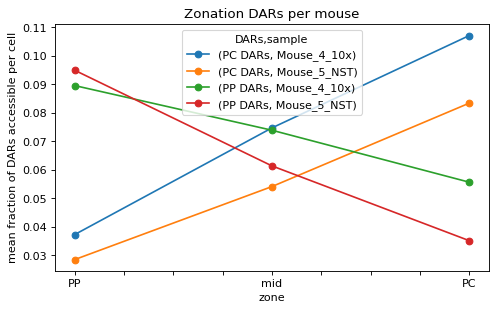

zone                    PP    mid     PC
DARs    sample                          
PC DARs Mouse_4_10x  0.037  0.075  0.107
        Mouse_5_NST  0.028  0.054  0.083
PP DARs Mouse_4_10x  0.090  0.074  0.056
        Mouse_5_NST  0.095  0.061  0.035

In [8]:
hep = adata[adata.obs["zone"].isin(["PP", "mid", "PC"])]
rows = []
for label, regions in [("PC DARs", sorted(robust_pc)), ("PP DARs", sorted(robust_pp))]:
    acc = np.asarray((hep[:, regions].X > 0).mean(axis=1)).ravel()  # per cell: fraction of the DARs accessible
    for (sample, zone), value in pd.Series(acc).groupby([hep.obs["sample"].values, hep.obs["zone"].values]).mean().items():
        rows.append({"DARs": label, "sample": sample, "zone": zone, "accessibility": value})
# one row per DAR set and mouse, one column per zone
summary = pd.DataFrame(rows).pivot_table(index=["DARs", "sample"], columns="zone", values="accessibility")[["PP", "mid", "PC"]]
summary.T.plot(marker="o", figsize=(7, 4), ylabel="mean fraction of DARs accessible per cell", title="Zonation DARs per mouse")
plt.show()
summary.round(3)

In both mice, the PC DARs become more accessible from PP over mid to PC hepatocytes, and the PP DARs less: a gradient, as expected for zonation, and the same in both animals and both nuclei isolation protocols. The absolute values differ between the mice (another sign of the batch effect), but the direction does not.

## Step 6: Saving the results

In [9]:
def write_bed(regions, path):
    # "chr:start-end" names -> three BED columns, sorted
    df = pd.Series(sorted(regions)).str.extract(r"(.+):(\d+)-(\d+)")
    df.to_csv(path, sep="\t", header=False, index=False)

write_bed(robust_pc, "zonation_DARs_PC.bed")
write_bed(robust_pp, "zonation_DARs_PP.bed")
os.makedirs("celltype_markers", exist_ok=True)
for cell_type, regions in markers.items():
    write_bed(regions, f"celltype_markers/{cell_type}.bed")
print(sorted(os.listdir(".")))

['celltype_markers', 'zonation_DARs_PC.bed', 'zonation_DARs_PP.bed']


## Step 7: Pseudobulk coverage tracks for IGV

To look at the DARs in a genome browser we need the accessibility signal of each group of cells. pycisTopic's `export_pseudobulk` collects the fragments of all cells of a group (from both mice) into one pseudobulk fragment file and writes a coverage track (bigWig, normalised to counts per million). We make tracks for the three hepatocyte zones and the three largest non-parenchymal cell types; the other cell types have too few cells for a clean track. This takes about 5 minutes and writes about 1 GB of bigWig files (and 3 GB of fragment files).

In [10]:
from pycisTopic.pseudobulk_peak_calling import export_pseudobulk

# fragment files of the two mice (the paths stored in the cisTopic object may point elsewhere)
FRAGMENTS = {s: f"{SC}/fragments/{s}.fragments.tsv.gz" for s in ["Mouse_4_10x", "Mouse_5_NST"]}
chromsizes = pd.read_table(f"{GENOME}/mm10.chrom.sizes", header=None, names=["Chromosome", "End"])
chromsizes.insert(1, "Start", 0)

# one group per hepatocyte zone, the cell type for the other cells
cell_data = cistopic_obj.cell_data.copy()
cell_data["pseudobulk"] = np.where(cell_data["cell_type"] == "Hepatocyte",
                                   "Hepatocyte_" + cell_data["zone"].astype(str), cell_data["cell_type"].astype(str))
groups = ["Hepatocyte_PC", "Hepatocyte_mid", "Hepatocyte_PP", "LSEC", "HSC", "Kupffer"]
cell_data = cell_data[cell_data["pseudobulk"].isin(groups)]

# bed_path: pseudobulk fragment files; bigwig_path: coverage tracks; split_pattern: separator of barcode and sample in the cell names
bw_paths, bed_paths = export_pseudobulk(
    cell_data, variable="pseudobulk", chromsizes=chromsizes, path_to_fragments=FRAGMENTS,
    sample_id_col="sample_id", split_pattern="___", normalize_bigwig=True, n_cpu=4,
    bed_path="pseudobulk/fragments", bigwig_path="pseudobulk", temp_dir="pseudobulk/tmp")
bw_paths

2026-10-28 23:18:33 - INFO - Splitting fragments by cell type.
2026-10-28 23:21:56 - INFO - generating bigwig files


{'Hepatocyte_PP': 'pseudobulk/Hepatocyte_PP.bw',
 'Hepatocyte_mid': 'pseudobulk/Hepatocyte_mid.bw',
 'HSC': 'pseudobulk/HSC.bw',
 'Hepatocyte_PC': 'pseudobulk/Hepatocyte_PC.bw',
 'LSEC': 'pseudobulk/LSEC.bw',
 'Kupffer': 'pseudobulk/Kupffer.bw'}

### In IGV

Download the six bigWig files (`pseudobulk/*.bw`) and the two zonation DAR files (`zonation_DARs_PC.bed`, `zonation_DARs_PP.bed`) and load them in [IGV](https://igv.org/app/) with genome **mm10**. Order the hepatocyte tracks PC, mid, PP, select them and choose *Group Autoscale*, so they share the same y-axis. Group-autoscaling all six tracks shows how the hepatocytes compare with the other cell types, but the strong promoter peaks of the non-parenchymal cells can make the hepatocyte tracks look flat.

Pericentral genes (the signal should increase from PP to PC):

- ***Glul*** (type `Glul` in the search box): the promoter is accessible in all zones, but a cluster of four PC DARs just downstream of the gene (chr1:153,909,900-153,912,400) is open almost only in pericentral hepatocytes (10-35× more signal in PC than in PP), and another PC DAR lies about 2 kb upstream of the TSS (about 15×).
- ***Cyp2e1***: about ten PC DARs spread over the gene and its surroundings, which open together; the strongest (around chr7:140,769,000-140,776,000) have more than ten times more signal in PC than in PP.
- ***Lgr5*** and ***Oat***: PC DARs with a 6-15× difference. At *Oat*, the promoter is also strongly accessible in LSEC.

Periportal genes (the signal should increase from PC to PP):

- ***Sds***: the promoter DAR has about 16× more signal in PP than in PC.
- ***Cyp2f2***: eight PP DARs, including the promoter (about 10× more signal in PP).
- ***Hal***: the promoter shows a smooth gradient, PC < mid < PP.

**Question**: At these loci, where is the mid track compared with PC and PP? Are the zonation DARs also accessible in LSEC, HSC and Kupffer cells? Which regions near these genes are accessible in all three hepatocyte zones?

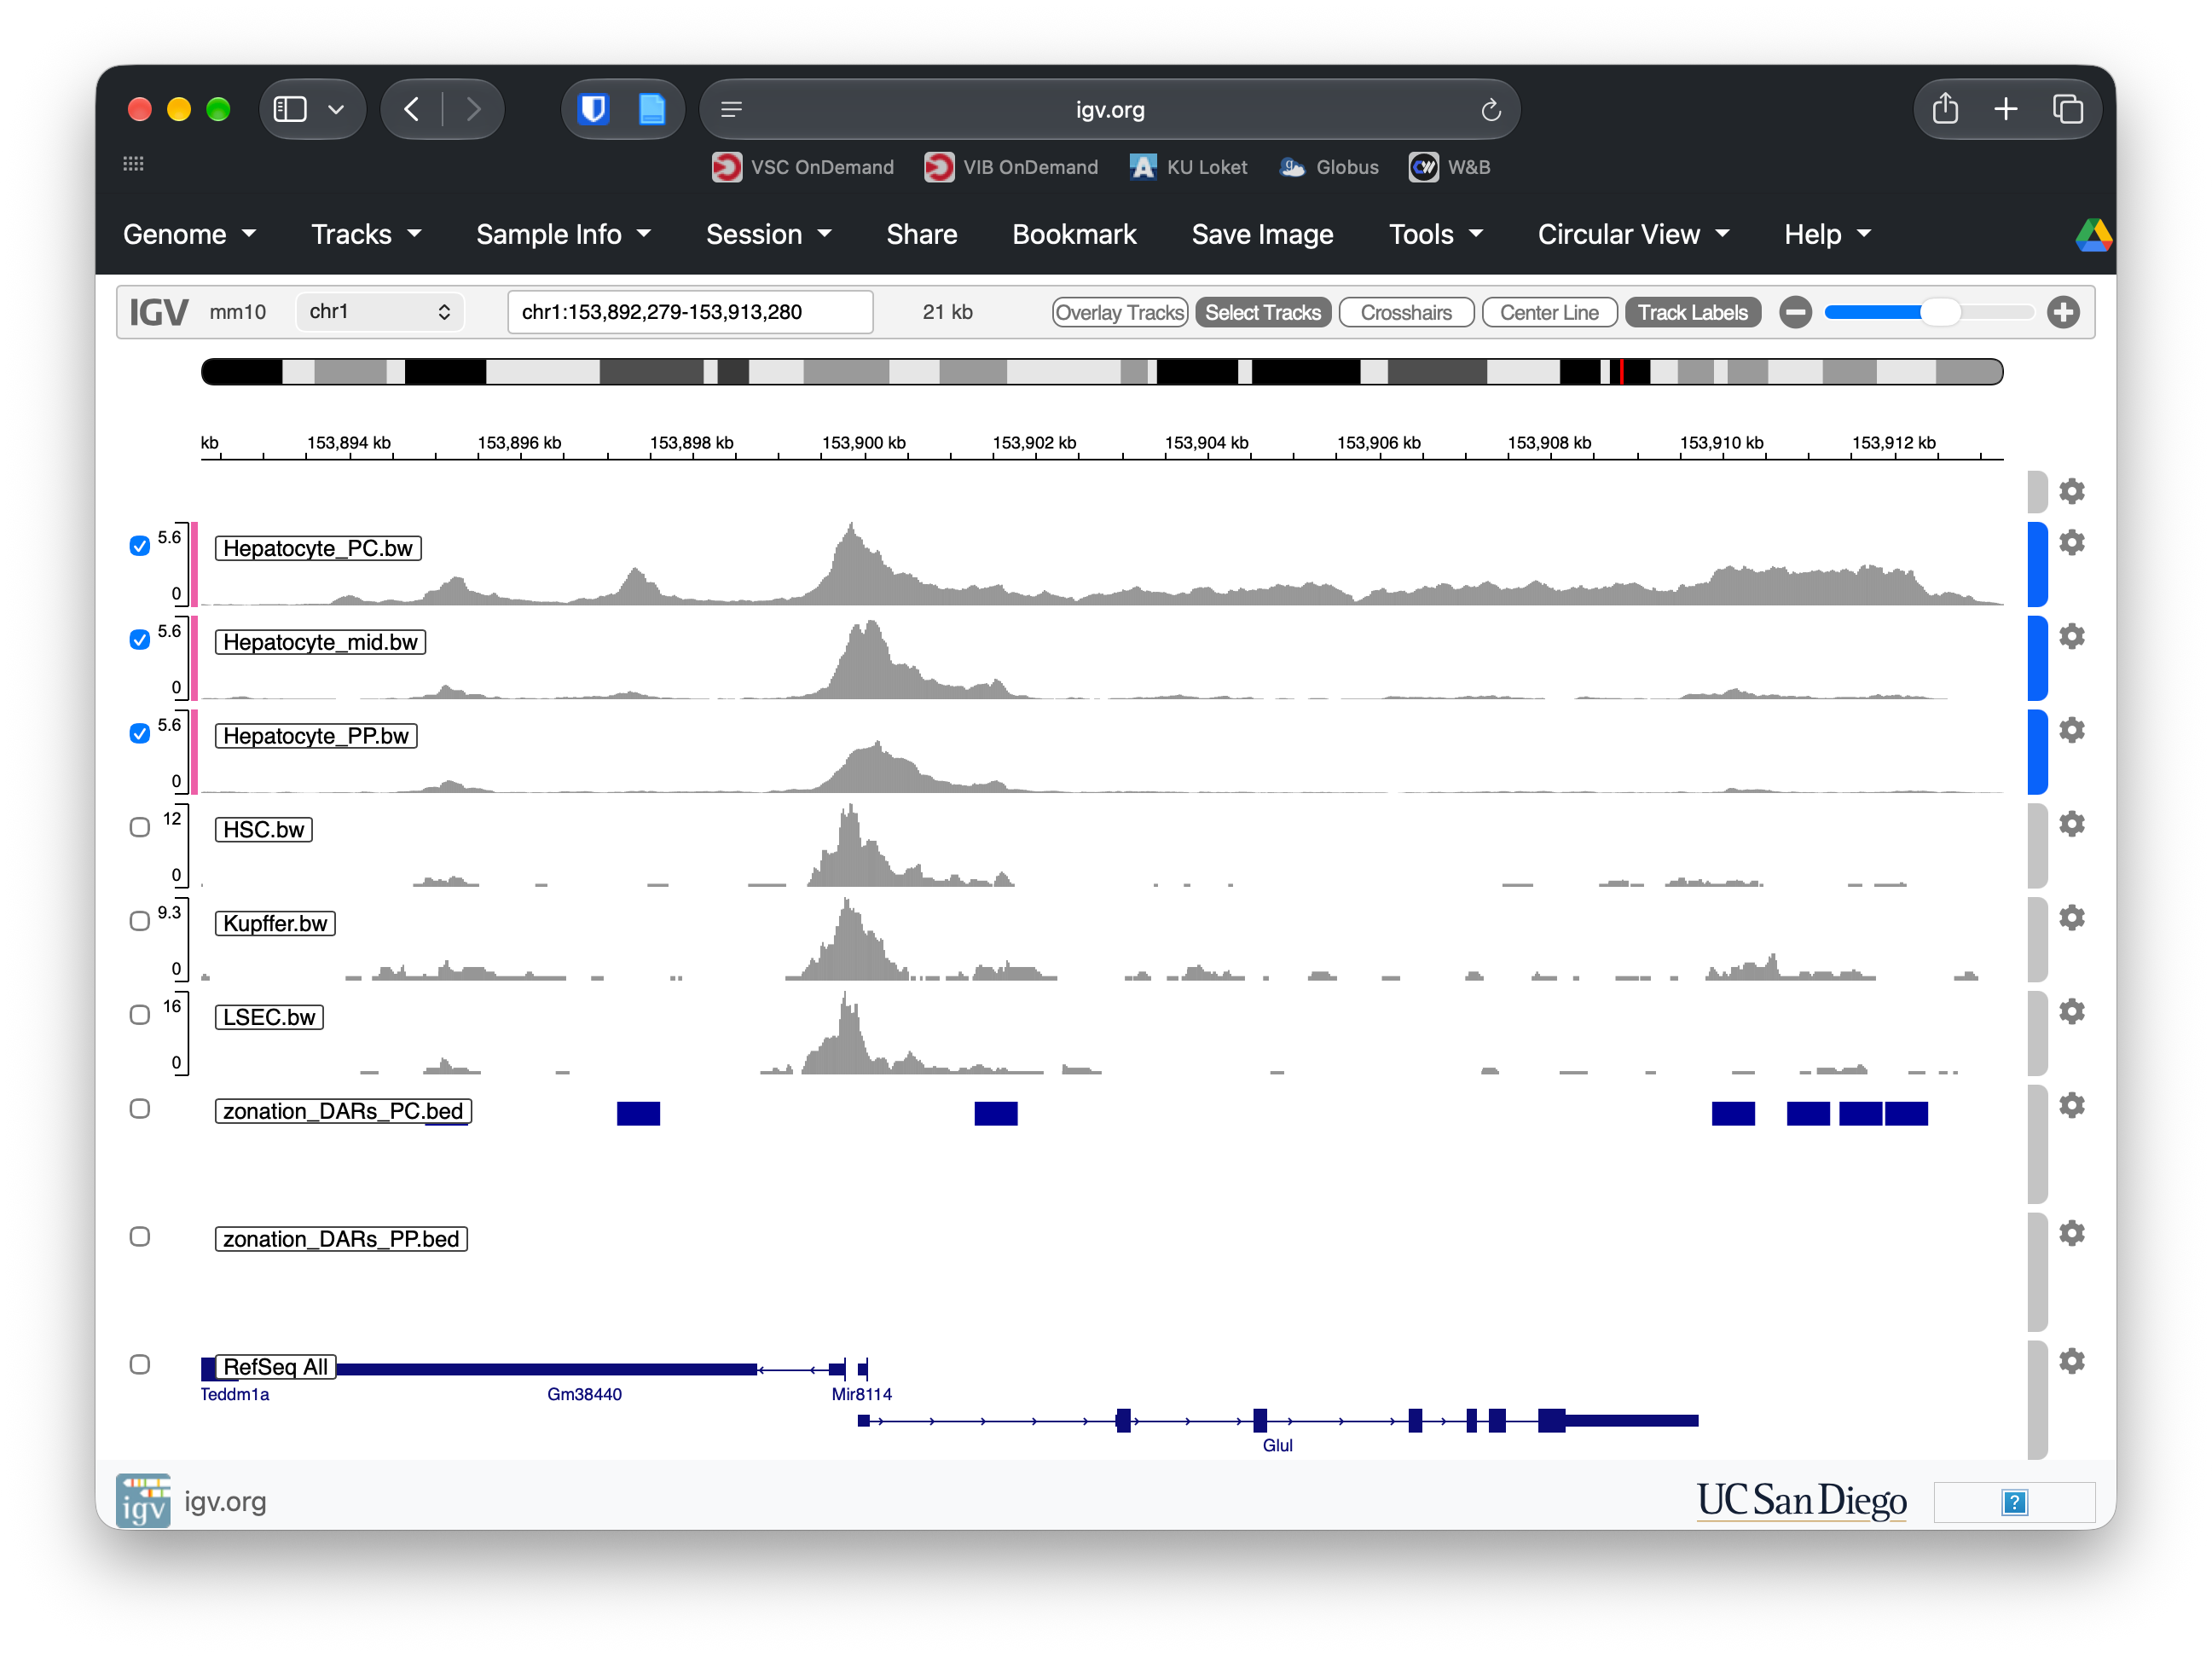

*Glul* (chr1, plus strand: the promoter is in the middle, the gene runs to the right). The three hepatocyte tracks share one scale; the non-parenchymal cells are scaled separately. The promoter is accessible in every cell type and in all three hepatocyte zones. The zonation lies on both sides of the gene: a PC DAR about 2 kb upstream of the promoter, with a peak only in the pericentral track, and a cluster of PC DARs just downstream of the gene, where only the pericentral hepatocytes have signal and the mid and PP tracks are almost flat.

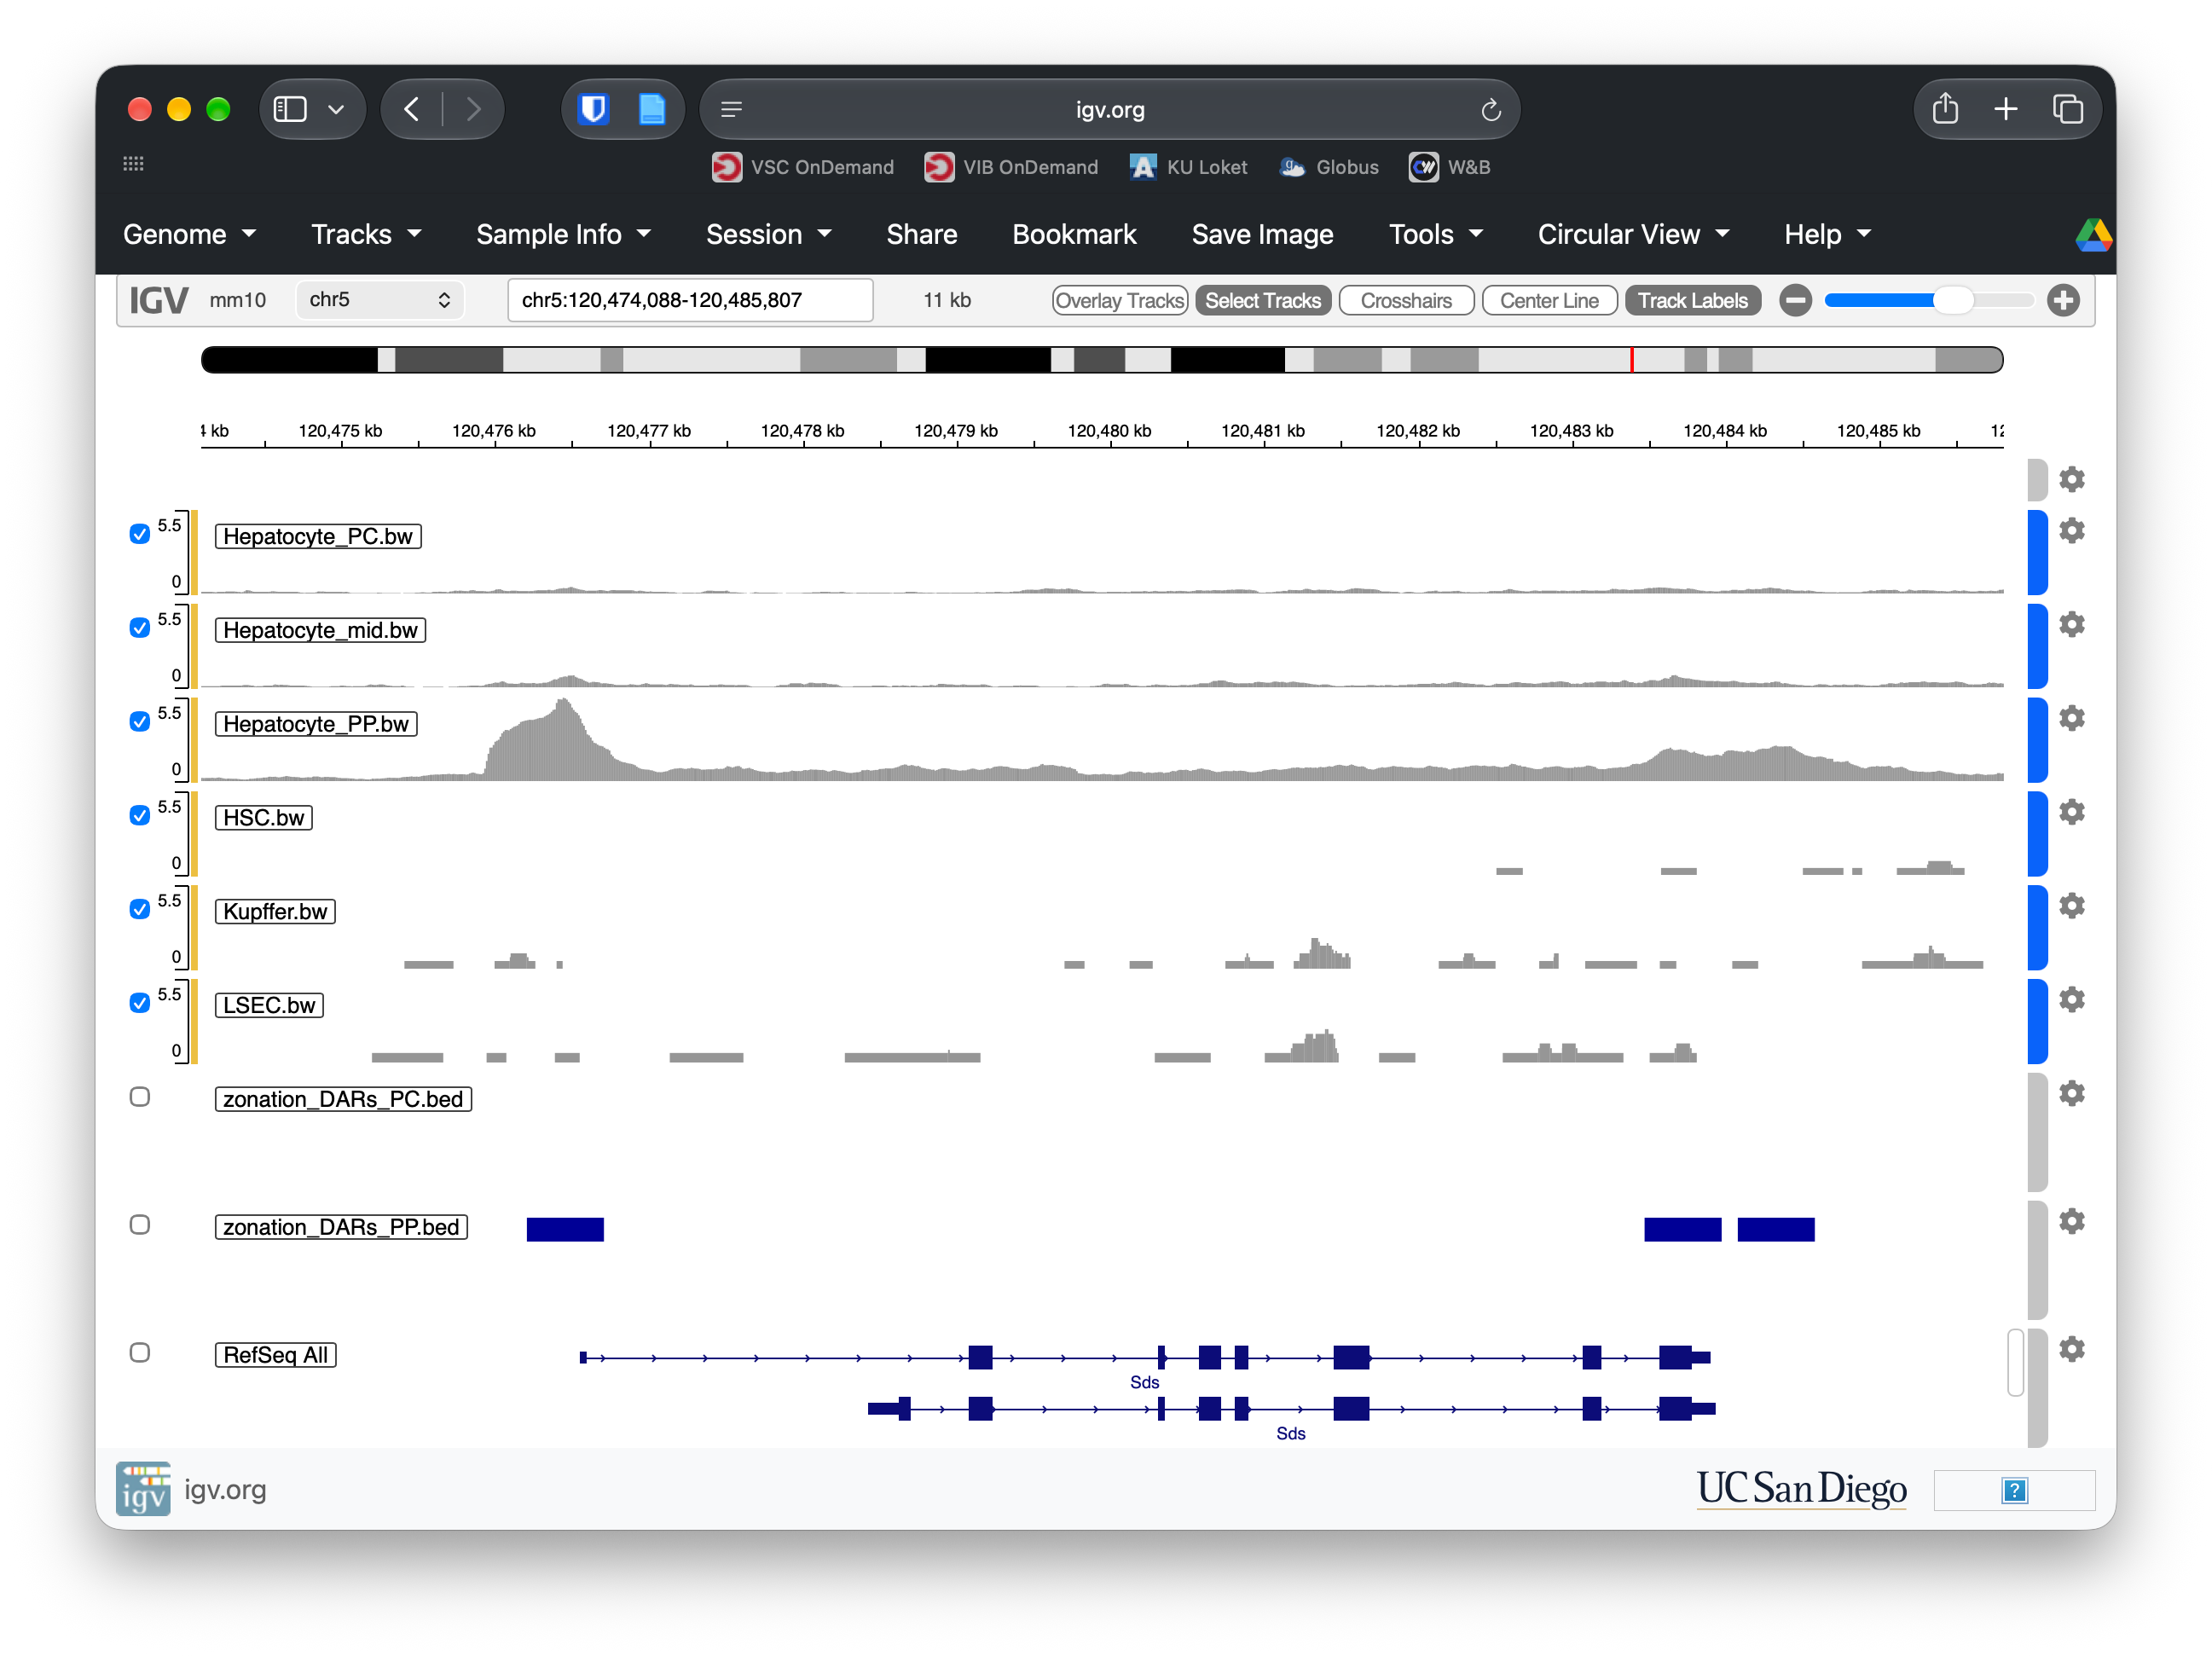

*Sds* (chr5, plus strand, two transcripts with different start sites). The periportal track shows clear signal at the upstream promoter (left) and over the 3' end of the gene (right); both are robust PP DARs. The PC and mid tracks are almost flat, and the non-parenchymal cells have no signal at these sites: a periportal, hepatocyte-specific regulatory landscape.

## Comparison with the paper

Bravo González-Blas et al. analysed these two samples together with more liver samples (scATAC-seq and Multiome), with pycisTopic. What we can compare directly:

| | this practical | paper |
|---|---|---|
| cells (Mouse_4 + Mouse_5) | 11,297: the paper's annotated cells that also pass our ATAC QC | 11,691 (7,518 + 4,173), selected with ATAC and RNA QC |
| consensus peaks | 203,415 (pseudobulk per cell type and zone, two samples) | 486,888 (more samples, more cells and cell types) |
| overlap of the peaks | 93% of ours overlap one of theirs | |
| cell types | every major cell type has its own ATAC cluster | RNA-based labels (used here as the reference) |
| zonation | hepatocyte clusters, topics and DARs follow the PP-PC axis | zonation analysed in depth, with spatial data and deep learning |

With two samples and standard tools, we recover the main structure of the paper's data: the same regions, the same cell types and the same zonation axis. The paper goes further: it links the zonated regions to transcription factors and to gene expression in space, which needs more data and methods beyond this practical.

## Conclusion

1. **Can cell types be recovered from accessibility alone?** Yes. Both pycisTopic and SnapATAC2 give every major liver cell type its own cluster, and thousands of cell-type-specific DARs. The low ARIs with the RNA labels come from the hepatocytes, which both tools split into several clusters.
2. **Is zonation visible in the chromatin?** Yes. The hepatocyte clusters, several topics and thousands of DARs follow the periportal-pericentral axis, in both mice and with both protocols.
3. **Which regions differ between PC and PP hepatocytes?** About 1,500 regions are more accessible in pericentral and about 740 in periportal hepatocytes according to both tools. They lie near the classic zonated genes: *Cyp2e1*, *Glul*, *Oat*, *Cyp1a2*, *Cyp7a1* and the Wnt targets *Axin2* and *Lgr5* for pericentral; *Cyp2f2*, *Hal*, *Sds*, *Cps1*, *Arg1* and *Pck1* for periportal. Their accessibility changes gradually from PP over mid to PC.

What to remember beyond this dataset:

- **Cell-type DARs** are abundant and specific: they mark the regulatory landscape of each liver cell type. **Zonation DARs** within hepatocytes are subtler, and different tools find different numbers; regions found by both, in the same direction, are the most robust.
- In single-cell data, **cells are not replicates of the experiment**: thousands of cells from two mice. Account for the sample (covariates, per-sample checks, or pseudobulk per mouse) before trusting very small p-values.

Single-cell ATAC-seq tells us *which* regions change along the zonation axis, but, like single-nucleus RNA-seq, it loses the position of the cells in the tissue: the zones here are inferred from gene expression. The [spatial transcriptomics practical](../spatial-transcriptomics/index.md) shows the same zonation genes (*Glul*, *Cyp2e1*, *Cyp2f2*, *Hal*) in their real positions around the central and portal veins, and the [single-nucleus RNA-seq practical](../single-nucleus-rna-seq/index.md) shows the matching expression programs.

The BED files and the pseudobulk tracks can be loaded in IGV, and the BED files can be used for motif enrichment to find the transcription factors behind each cell type and zone.

## Exercises

1. Which genes have the most robust PC DARs nearby (within 50 kb)? Count the robust PC DARs per nearest gene (`genes_pc`, column `Distance`) and list the top 15; do the same for PP. Do you recognise liver zonation genes? Which genes are new to you?
2. Repeat the SnapATAC2 zonation test with a stricter fold-change threshold (`min_log_fc=0.5`). How many DARs remain in each mouse, and in both?
3. Add the zonation topic regions of [part 2](part_2_pycistopic.ipynb) (`topic_regions/`) to your IGV session, and look at *Cyp2e1* and *Cyp2f2*. Do the topics and the DARs mark the same regions? Are there regions in the topics that change between the PC and PP tracks but are not DARs?